**Initialization, unzipping of data,  supporting functions**


In [1]:
import sys; sys.path.insert(0, "."); sys.path.insert(1, "..") 
import ast
import matplotlib.pyplot as plt
import os
import train

# unzip data files (run only once)
if not os.path.isfile('../data/4.train'): 
    print("unzipping")
    !ls ../data/*
    !gunzip -k ../data/*




**Training the model for one epoch (5 loop)**

In [2]:
# you can change model parameters here, the rest are the default
my_params= {'reload_data':'amplitude:../data/5.train',
         'eval_data':'../data/5.test', 
         'eval_size':-1,
         'epoch_size':100000,
         'max_epoch': 1
         }


parser = train.get_parser()
params = parser.parse_args([])

# update model params with the ones selected abov
for k,v in my_params.items():
    setattr(params,k,v)
    

# check parameters and run the model
train.check_model_params(params)
train.main(params)




INFO - 11/15/26 12:41:43 - 0:00:00 - ============ Initialized logger ============
INFO - 11/15/26 12:41:43 - 0:00:00 - activation: gelu
                                     amp: False
                                     architecture: encoder_decoder
                                     attention_dropout: 0
                                     base: 1000
                                     batch_size: 32
                                     batch_size_eval: 128
                                     beam_eval: False
                                     beam_length_penalty: 1
                                     beam_size: 1
                                     clip_grad_norm: 5
                                     command: /opt/anaconda3/lib/python3.13/site-packages/ipykernel_launcher.py -f /Users/francoischarton/Library/Jupyter/runtime/kernel-68f344f7-c8e5-41dc-9feb-918730b2467e.json --exp_id 2026_11_15_12_41_43
                                     cpu: False
                          

**Logs and lodel save files,  Loss curve of the previous trained model**

In [2]:
# support functions (read the files, param is the train.log file path)
def read_losses(filename):
    res = []
    with open(filename, 'rt') as f:
        for line in f:
            if line.find("- LOSS") >=0:
                res.append(float(line.split(' ')[-4]))
    return res

def read_logs(filename):
    logs=[]
    with open(filename, 'rt') as f:
        for line in f:
            pos = line.find('__log__:')
            if pos >=0:
                dic = ast.literal_eval(line[pos+8:])
                logs.append(dic)
    return logs

def draw_train_loss(file,graph):
    loss = read_losses(file)

    graph.plot(loss,linewidth=1)
    graph.title("training loss")
    
def draw_test_loss(file,graph):
    indicators = ["xe_loss"]
    prefix = "valid_AMPLITUDE_"
    perf = read_logs(file)
    v1 = [p[prefix+'xe_loss'] for p in perf]
    graph.plot(v1,linewidth=1,label="Accuracy")
    graph.title("Test loss")
    
def draw_accuracy(file,graph):
    indicators = ["avg_correct_sign","avg_correct_module"]
    prefix = "valid_AMPLITUDE_"
    perf = read_logs(file)

    v1 = [p[prefix+"acc"]/100.0 for p in perf]

    graph.plot(v1,linewidth=1,label="Accuracy")
    for i in indicators:
        v = [p[prefix+i] for p in perf]
        graph.plot(v, linewidth=1, label=i)

    graph.title("Accuracy")
    graph.legend()
    


In [3]:



path = params.dump_path

print(f'All results are dumped into {path}')
print()
!ls -l {path}

print()
print("checkpoint.pth constains the model weights")
print("train.log the experiment log")

logfile = os.path.join(path,"train.log")

#loss = read_losses(logfile)

#plt.plot(loss,linewidth=1)
#plt.title("training loss")

draw_train-loss(logfile,plt)
plt.rcParams['figure.figsize'] = [10,10]
plt.show()


last_perf = read_logs(logfile)[-1]
print()
print("Final performances")
for s in last_perf:
    print(s, ":" , last_perf[s])


NameError: name 'params' is not defined

**Data saved in /checkpoint (loop 6, unique coefficients, 39 epochs) loss curve**

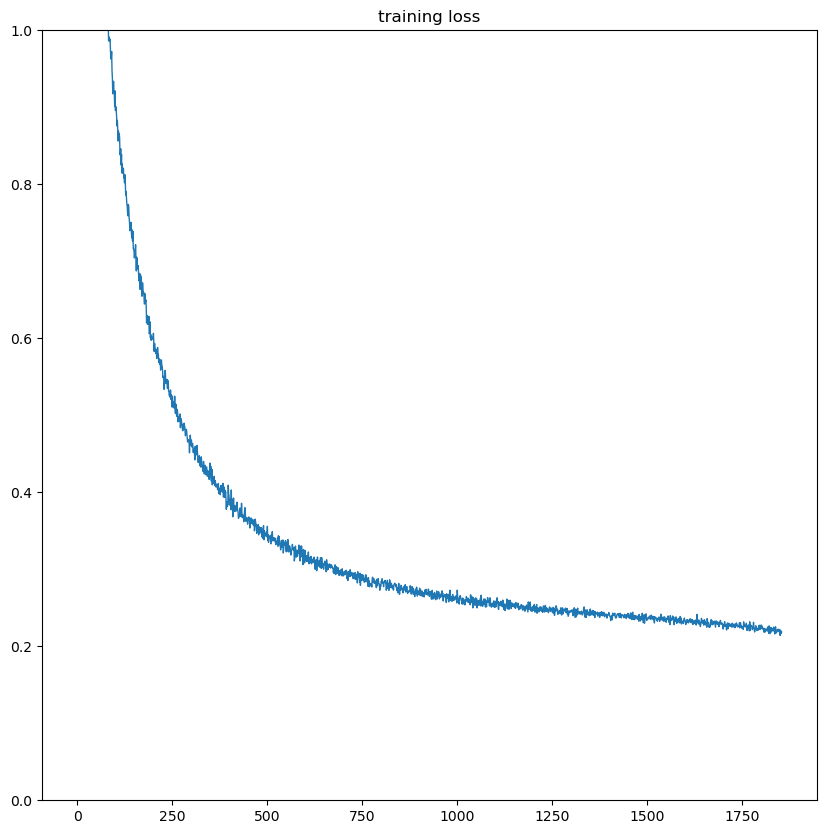

In [6]:
path = '../checkpoint/'

logfile = os.path.join(path,"train.log")

loss = read_losses(logfile)

plt.plot(loss,linewidth=1)
plt.ylim(0,1)
plt.title("training loss")
plt.rcParams['figure.figsize'] = [10,10]
plt.show()




**Accuracies/signs/modules**

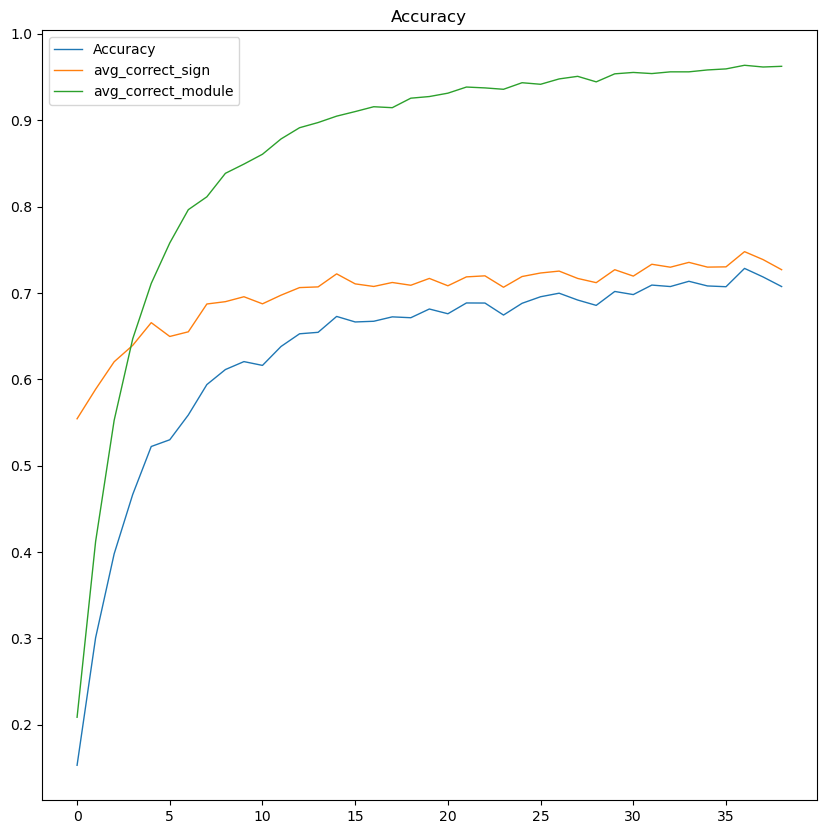

In [7]:
indicators = ["avg_correct_sign","avg_correct_module"]
prefix = "valid_AMPLITUDE_"


perf = read_logs(logfile)

v1 = [p[prefix+"acc"]/100.0 for p in perf]

plt.plot(v1,linewidth=1,label="Accuracy")
for i in indicators:
    v = [p[prefix+i] for p in perf]
    plt.plot(v, linewidth=1, label=i)

plt.title("Accuracy")
plt.legend()
plt.rcParams['figure.figsize'] = [10,10]
plt.show()




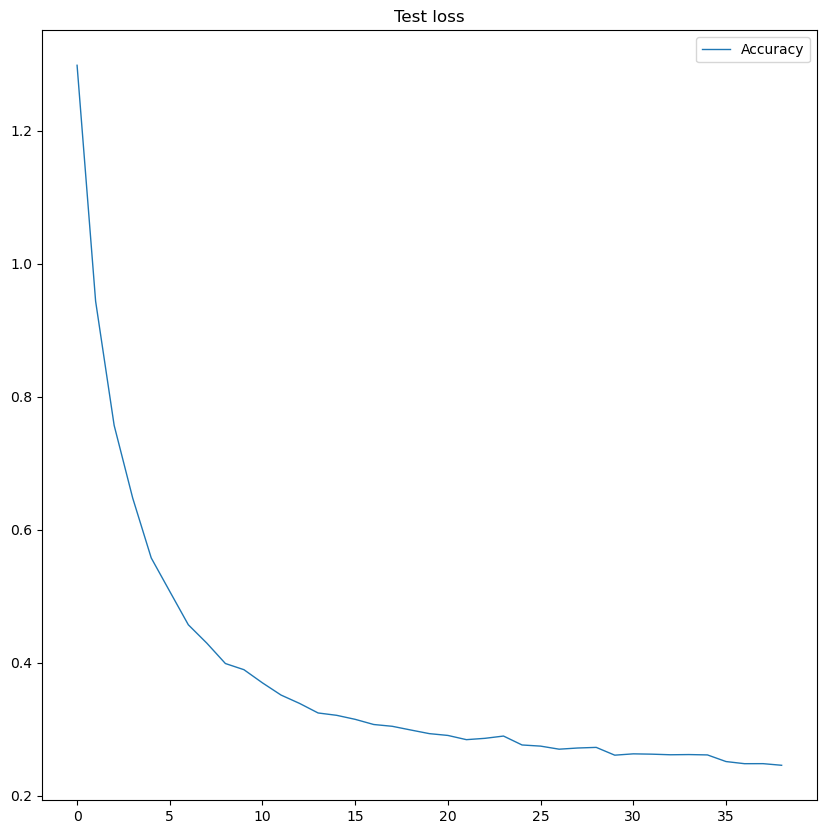

In [8]:
indicators = ["xe_loss"]
prefix = "valid_AMPLITUDE_"


perf = read_logs(logfile)

v1 = [p[prefix+'xe_loss'] for p in perf]

plt.plot(v1,linewidth=1,label="Accuracy")

plt.title("Test loss")
plt.legend()
plt.rcParams['figure.figsize'] = [10,10]
plt.show()

**overfitting with small models (5 minutes to run)**

In [16]:
# you can change model parameters here, the rest are the default
# max_eamples 5k (12.5% of dataset) slight overfit, 10k slight (25%), 20k (50%) almost none 

my_params= {'reload_data':'amplitude:../data/5u.train',
         'eval_data':'../data/5u.test', 
         'eval_size':-1,
         'epoch_size':100000,
         'max_epoch': 15,
         'max_examples':5000,
        'batch_size_eval':1000,
        'batch_size':64,
        'n_enc_layers':1,
        'n_dec_layers':1,
         'enc_emb_dim':128,
         'dec_emb_dim':128,
         }


parser = train.get_parser()
params = parser.parse_args([])

# update model params with the ones selected abov
for k,v in my_params.items():
    setattr(params,k,v)
    

# check parameters and run the model
train.check_model_params(params)
train.main(params)




INFO - 11/15/26 16:12:24 - 0:05:15 - Rank 0/1, local_rank=0, is_master=True
INFO - 11/15/26 16:12:24 - 0:00:00 - ============ Initialized logger ============
INFO - 11/15/26 16:12:24 - 0:00:00 - activation: gelu
                                     amp: False
                                     architecture: encoder_decoder
                                     attention_dropout: 0
                                     base: 1000
                                     batch_size: 64
                                     batch_size_eval: 1000
                                     beam_eval: False
                                     beam_length_penalty: 1
                                     beam_size: 1
                                     clip_grad_norm: 5
                                     command: /opt/anaconda3/lib/python3.13/site-packages/ipykernel_launcher.py -f /Users/francoischarton/Library/Jupyter/runtime/kernel-68f344f7-c8e5-41dc-9feb-918730b2467e.json --exp_id 2026_11_15_16_12_

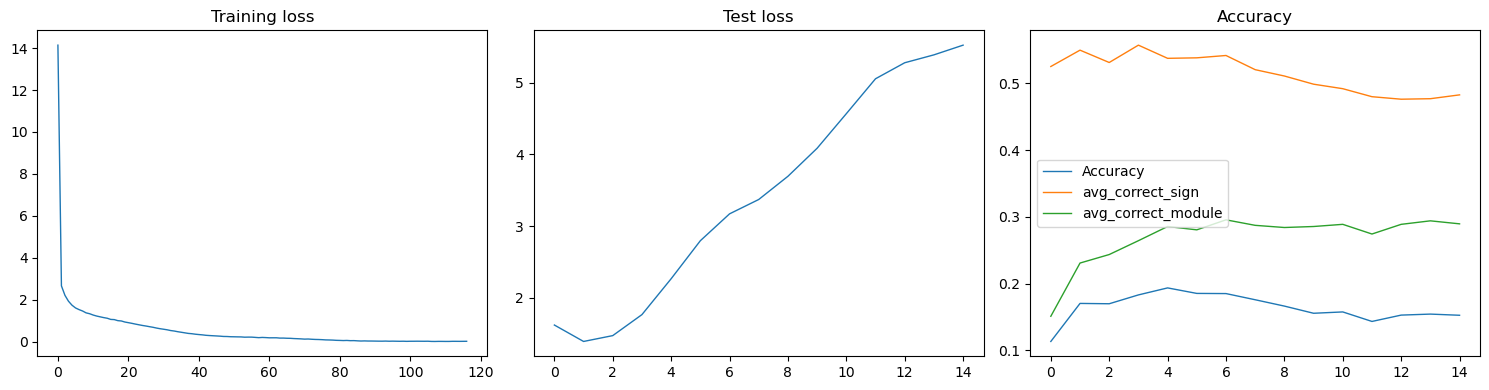

In [17]:
indicators = ["xe_loss"]
prefix = "valid_AMPLITUDE_"
logfile = os.path.join(params.dump_path,"train.log")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))   # 1 ligne, 3 colonnes



loss = read_losses(logfile)

axes[0].plot(loss,linewidth=1)
axes[0].set_title("Training loss")

perf = read_logs(logfile)

v1 = [p[prefix+'xe_loss'] for p in perf]

axes[1].plot(v1,linewidth=1)

axes[1].set_title("Test loss")

indicators = ["avg_correct_sign","avg_correct_module"]


perf = read_logs(logfile)

v1 = [p[prefix+"acc"]/100.0 for p in perf]

axes[2].plot(v1,linewidth=1,label="Accuracy")
for i in indicators:
    v = [p[prefix+i] for p in perf]
    axes[2].plot(v, linewidth=1, label=i)

axes[2].set_title("Accuracy")
axes[2].legend()
plt.tight_layout()
plt.show()


In [32]:

# Varying LR 0.01 doesn't learn, 0.001 does
# can try adgrad, sgd

my_params= {'reload_data':'amplitude:../data/5.train',
         'eval_data':'../data/5.valid', 
         'eval_size':-1,
         'epoch_size':100000,
         'max_epoch': 10,
         'max_examples':-1,
        'batch_size_eval':1000,
        'batch_size':64,
        'n_enc_layers':1,
        'n_dec_layers':1,
         'enc_emb_dim':128,
         'dec_emb_dim':128,
          'optimizer': "adam,lr=0.1",
         }


parser = train.get_parser()
params = parser.parse_args([])

# update model params with the ones selected abov
for k,v in my_params.items():
    setattr(params,k,v)
    

# check parameters and run the model
train.check_model_params(params)
train.main(params)


INFO - 11/15/26 16:48:26 - 0:01:03 - Rank 0/1, local_rank=0, is_master=True
INFO - 11/15/26 16:48:26 - 0:00:00 - ============ Initialized logger ============
INFO - 11/15/26 16:48:26 - 0:00:00 - activation: gelu
                                     amp: False
                                     architecture: encoder_decoder
                                     attention_dropout: 0
                                     base: 1000
                                     batch_size: 64
                                     batch_size_eval: 1000
                                     beam_eval: False
                                     beam_length_penalty: 1
                                     beam_size: 1
                                     clip_grad_norm: 5
                                     command: /opt/anaconda3/lib/python3.13/site-packages/ipykernel_launcher.py -f /Users/francoischarton/Library/Jupyter/runtime/kernel-68f344f7-c8e5-41dc-9feb-918730b2467e.json --exp_id 2026_11_15_16_48_

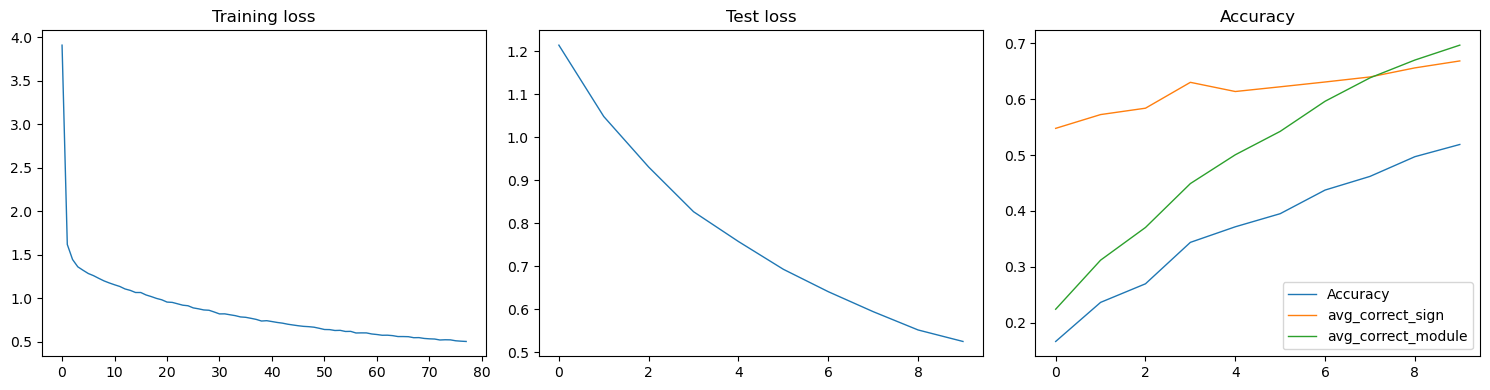

In [28]:
indicators = ["xe_loss"]
prefix = "valid_AMPLITUDE_"
logfile = os.path.join(params.dump_path,"train.log")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))   # 1 ligne, 3 colonnes



loss = read_losses(logfile)

axes[0].plot(loss,linewidth=1)
axes[0].set_title("Training loss")

perf = read_logs(logfile)

v1 = [p[prefix+'xe_loss'] for p in perf]

axes[1].plot(v1,linewidth=1)

axes[1].set_title("Test loss")

indicators = ["avg_correct_sign","avg_correct_module"]


perf = read_logs(logfile)

v1 = [p[prefix+"acc"]/100.0 for p in perf]

axes[2].plot(v1,linewidth=1,label="Accuracy")
for i in indicators:
    v = [p[prefix+i] for p in perf]
    axes[2].plot(v, linewidth=1, label=i)

axes[2].set_title("Accuracy")
axes[2].legend()
plt.tight_layout()
plt.show()
